# Start Trek — DQN sur LunarLander-v3

**Objectif :** entraîner un agent qui fait atterrir le module lunaire tout seul, avec un **Deep Q-Network (DQN)**.
L'environnement est résolu avec un **score moyen ≥ 200 sur 100 épisodes**.

**Plan**
1. L'environnement
2. Agent aléatoire (baseline)
3. Replay buffer
4. Réseau de neurones et loss
5. Agent DQN : epsilon-greedy et target network
6. Hyperparamètres
7. Boucle d'entraînement
8. Courbes d'entraînement
9. Évaluation sur 100 épisodes
10. Résultats sur plusieurs seeds
11. Expérience : fréquence de mise à jour du target network
12. Conclusion

In [1]:
import json
import os
import random
import time
from collections import Counter, deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

## 1. L'environnement

- Pendant l'entraînement, on crée l'environnement **sans affichage** (`render_mode=None`) : afficher chaque image est très lent.
  L'affichage (`render_mode="human"`) servira seulement pour regarder l'agent jouer.
- La taille de l'état et le nombre d'actions sont **lus depuis l'environnement**, pas écrits à la main.

In [2]:
ENV_ID = "LunarLander-v3"


def make_env(render_mode=None):
    return gym.make(ENV_ID, render_mode=render_mode)


env = make_env()
STATE_DIM = env.observation_space.shape[0]
N_ACTIONS = env.action_space.n
env.close()

print("Taille de l'état :", STATE_DIM)
print("Nombre d'actions :", N_ACTIONS)

Taille de l'état : 8
Nombre d'actions : 4


### Reproductibilité

On fixe la graine de toutes les sources de hasard (Python, NumPy, PyTorch, et l'environnement avec `env.reset(seed=...)`)
pour que quelqu'un qui relance le notebook obtienne les mêmes résultats.

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

### Pourquoi un épisode se termine

| Cause | Comment on la détecte | Type |
|---|---|---|
| `crash` | le corps du module touche le sol (`env.unwrapped.game_over`) | terminated |
| `out` | le module sort de l'écran (`abs(x) >= 1`) | terminated |
| `rest` | le module est posé et ne bouge plus | terminated |
| `truncated` | la limite de 1000 steps est atteinte | truncated |

**`terminated` ≠ `truncated`** : un épisode *terminé* est vraiment fini, il n'y a plus de récompense à attendre.
Un épisode *tronqué* a juste été coupé, le module aurait pu continuer.

In [4]:
END_REASONS = ["crash", "out", "rest", "truncated"]


def end_reason(env, state, terminated, truncated):
    if terminated:
        if env.unwrapped.game_over:
            return "crash"
        if abs(state[0]) >= 1.0:
            return "out"
        return "rest"
    if truncated:
        return "truncated"
    return None

## 2. Agent aléatoire (baseline)

Avant d'entraîner quoi que ce soit, on fait jouer un agent qui choisit ses actions **au hasard** pendant 100 épisodes.
Ça donne un **score de référence** à battre, et ça vérifie que notre boucle de jeu et notre logging
(score, nombre de steps, cause de fin) marchent.

In [5]:
def run_episode(env, policy, seed=None):
    state, _ = env.reset(seed=seed)
    total_reward, steps, done = 0.0, 0, False
    while not done:
        action = policy(state)
        state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        steps += 1
        done = terminated or truncated
    return total_reward, steps, end_reason(env, state, terminated, truncated)

Épisode 0 : score = -190.0, steps = 66, fin = crash
Épisode 1 : score = -291.5, steps = 114, fin = crash
Épisode 2 : score = -291.5, steps = 87, fin = crash
Épisode 3 : score = -121.8, steps = 90, fin = crash
Épisode 4 : score = -460.8, steps = 134, fin = crash

Moyenne sur 100 épisodes : -192.1 (écart-type 114.4)
Causes de fin : Counter({'crash': 92, 'out': 8})


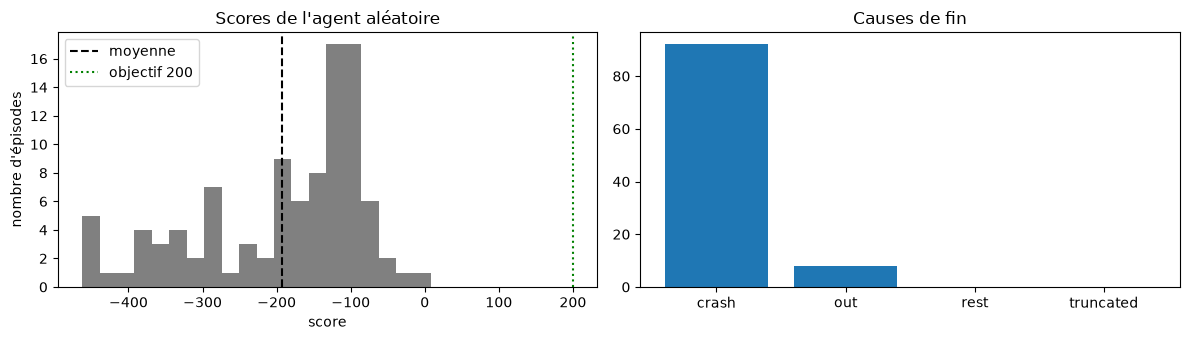

In [6]:
set_seed(0)
env = make_env()
env.action_space.seed(0)

scores, reasons = [], []
for i in range(100):
    score, steps, reason = run_episode(env, lambda s: env.action_space.sample(), seed=i)
    scores.append(score)
    reasons.append(reason)
    if i < 5:
        print(f"Épisode {i} : score = {score:.1f}, steps = {steps}, fin = {reason}")
env.close()

print(f"\nMoyenne sur 100 épisodes : {np.mean(scores):.1f} (écart-type {np.std(scores):.1f})")
print("Causes de fin :", Counter(reasons))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(scores, bins=20, color="gray")
axes[0].axvline(np.mean(scores), color="k", linestyle="--", label="moyenne")
axes[0].axvline(200, color="green", linestyle=":", label="objectif 200")
axes[0].set_xlabel("score"); axes[0].set_ylabel("nombre d'épisodes"); axes[0].legend()
axes[0].set_title("Scores de l'agent aléatoire")
axes[1].bar(END_REASONS, [reasons.count(r) for r in END_REASONS])
axes[1].set_title("Causes de fin")
plt.tight_layout(); plt.show()

**Lecture :** l'agent aléatoire s'écrase presque à chaque fois et n'atteint jamais 200. C'est notre point de départ.

## 3. Replay buffer

Deux steps qui se suivent sont presque identiques. Si le réseau apprend dessus dans l'ordre, il apprend mal.
On garde donc les transitions `(state, action, reward, next_state, done)` dans une **mémoire**, et on apprend
sur des **lots tirés au hasard** dedans. En plus, chaque transition peut servir plusieurs fois.

- **Taille maximale fixe** : on utilise une `deque(maxlen=capacity)`. Quand elle est pleine, la plus ancienne transition est supprimée toute seule.
- **Lot aléatoire** : `sample(batch_size)` tire des transitions au hasard et les renvoie **en tenseurs groupés par élément**
  (tous les états ensemble, toutes les actions ensemble...), prêts pour le réseau.
- **Taille actuelle** : `len(buffer)`, pour ne pas commencer à apprendre trop tôt.

**Que mettre dans `done` ?** Seulement `terminated`. Si l'épisode a été coupé à 1000 steps, le module aurait pu continuer :
il ne faut pas faire croire au réseau qu'il n'y a plus rien après.

In [7]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.memory, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (torch.tensor(np.array(states), dtype=torch.float32),
                torch.tensor(actions, dtype=torch.int64),
                torch.tensor(rewards, dtype=torch.float32),
                torch.tensor(np.array(next_states), dtype=torch.float32),
                torch.tensor(dones, dtype=torch.float32))

    def __len__(self):
        return len(self.memory)

**Test :** une mémoire de taille 5, dans laquelle on ajoute 7 transitions (récompenses 0 à 6).
Elle doit en garder 5, et les deux plus anciennes (0 et 1) doivent avoir disparu.

In [8]:
test_buffer = ReplayBuffer(capacity=5)
for i in range(7):
    test_buffer.add(np.zeros(STATE_DIM), 0, float(i), np.zeros(STATE_DIM), 0.0)

print("Taille :", len(test_buffer))
print("Récompenses gardées :", [t[2] for t in test_buffer.memory])

states, actions, rewards, next_states, dones = test_buffer.sample(3)
print("Forme des états d'un lot de 3 :", states.shape)

Taille : 5
Récompenses gardées : [2.0, 3.0, 4.0, 5.0, 6.0]
Forme des états d'un lot de 3 : torch.Size([3, 8])


## 4. Réseau de neurones et loss

Une **Q-value** $Q(s, a)$, c'est le total de points que l'agent peut espérer s'il joue l'action $a$ dans l'état $s$.
Comme l'état est fait de nombres réels, on ne peut pas faire un tableau de toutes les Q-values : un **réseau de neurones** les estime.

**Architecture :** `8 → 128 → 128 → 4`, avec ReLU.
- **Entrée** : les 8 valeurs de l'état.
- **Sortie** : une Q-value par action (4). Pas d'activation à la fin, car une Q-value peut être négative.
- Deux couches de 128 : l'état est petit, un petit réseau suffit.

**Loss :** pour chaque transition $(s, a, r, s', done)$ du lot, on calcule une **cible** avec l'équation de Bellman :

$$\text{cible} = r + \gamma \cdot (1 - done) \cdot \max_{a'} Q_{target}(s', a')$$

Puis la **MSE** entre la Q-value prédite et la cible :

$$\mathcal{L} = \frac{1}{N} \sum \big(Q(s, a) - \text{cible}\big)^2$$

- Si `done = 1`, l'épisode est vraiment fini : la cible vaut juste $r$.
- La cible est calculée avec le **target network** (section 5), sans gradient.

In [9]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, n_actions),
        )

    def forward(self, x):
        return self.net(x)


print(QNetwork(STATE_DIM, N_ACTIONS))

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)


## 5. Agent DQN

### Epsilon-greedy
- avec une probabilité $\varepsilon$ : action **au hasard** (exploration) ;
- sinon : action qui a la **plus grande Q-value** (exploitation).

$\varepsilon$ commence à 1 (l'agent ne sait rien) et diminue au fil de l'entraînement.
En évaluation, on met $\varepsilon = 0$ : l'agent joue toujours sa meilleure action.

### Target network
Si on calcule la cible avec le réseau qu'on est en train d'entraîner, la cible bouge à chaque update : c'est instable.
On utilise donc une **copie** du réseau, le target network, qui sert seulement à calculer les cibles.

**Mise à jour :** on recopie le réseau principal dans le target network **tous les `target_update` updates** (hard update),
comme dans le DQN d'origine. Entre deux copies, la cible ne bouge pas. On essaiera plus tard une mise à jour
plus progressive (soft update) pour comparer.

In [10]:
class DQNAgent:
    def __init__(self, state_dim, n_actions, lr=5e-4, gamma=0.99, target_update=1000):
        self.n_actions = n_actions
        self.gamma = gamma
        self.target_update = target_update
        self.q_net = QNetwork(state_dim, n_actions)
        self.target_net = QNetwork(state_dim, n_actions)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.optimizer = torch.optim.Adam(self.q_net.parameters(), lr=lr)
        self.n_updates = 0

    def act(self, state, epsilon=0.0):
        if random.random() < epsilon:
            return random.randrange(self.n_actions)
        with torch.no_grad():
            q_values = self.q_net(torch.tensor(state, dtype=torch.float32))
        return int(q_values.argmax())

    def learn(self, batch):
        states, actions, rewards, next_states, dones = batch

        # Q-value prédite pour l'action qui a été jouée
        q_values = self.q_net(states)
        q_pred = q_values[range(len(actions)), actions]

        # Cible de Bellman, calculée avec le target network
        with torch.no_grad():
            q_next = self.target_net(next_states).max(dim=1).values
            target = rewards + self.gamma * (1 - dones) * q_next

        loss = F.mse_loss(q_pred, target)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # Hard update : on recopie le réseau tous les target_update updates
        self.n_updates += 1
        if self.n_updates % self.target_update == 0:
            self.target_net.load_state_dict(self.q_net.state_dict())

        return loss.item()

**Test :** l'agent n'est pas encore entraîné. On vérifie qu'il joue au hasard avec $\varepsilon = 1$,
qu'il joue toujours la même action (sa meilleure) avec $\varepsilon = 0$, et qu'un pas d'apprentissage marche.

In [11]:
set_seed(0)
agent = DQNAgent(STATE_DIM, N_ACTIONS)

env = make_env()
env.action_space.seed(0)
state, _ = env.reset(seed=0)
print("ε = 1 :", [agent.act(state, epsilon=1.0) for _ in range(10)])
print("ε = 0 :", [agent.act(state, epsilon=0.0) for _ in range(10)])

# On remplit la mémoire avec 200 steps au hasard, puis on fait un pas d'apprentissage
buffer = ReplayBuffer(capacity=10_000)
for _ in range(200):
    action = env.action_space.sample()
    next_state, reward, terminated, truncated, _ = env.step(action)
    buffer.add(state, action, reward, next_state, float(terminated))
    if terminated or truncated:
        state, _ = env.reset()
    else:
        state = next_state
env.close()

print("Transitions en mémoire :", len(buffer))
print("Loss après un pas d'apprentissage :", round(agent.learn(buffer.sample(64)), 2))

ε = 1 : [3, 3, 2, 2, 1, 2, 0, 2, 1, 0]
ε = 0 : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Transitions en mémoire : 200
Loss après un pas d'apprentissage : 172.1


## 6. Hyperparamètres

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| `n_episodes` | 800 | **Budget en épisodes.** Un DQN de cette taille apprend LunarLander en quelques centaines d'épisodes ; 800 laisse de la marge. |
| `gamma` (γ) | 0.99 | L'atterrissage arrive après plusieurs centaines de steps : il faut tenir compte du futur lointain. |
| `lr` | 5e-4 | Taux d'apprentissage d'Adam, valeur courante pour un DQN. Plus grand : instable. Plus petit : lent. |
| `batch_size` | 64 | Taille des lots tirés dans le replay buffer, compromis classique. |
| `buffer_capacity` | 100 000 | Assez de souvenirs variés, sans garder trop de coups joués quand l'agent était encore mauvais. |
| `learning_starts` | 1 000 | On attend d'avoir assez de transitions avant de commencer à apprendre. |
| `train_every` | 4 | Un pas d'apprentissage tous les 4 steps : moins de calcul, et chaque transition sert quand même plusieurs fois. |
| `target_update` | 1 000 | On recopie le réseau dans le target network tous les 1 000 pas d'apprentissage. |
| `eps_start` / `eps_end` / `eps_decay` | 1.0 / 0.01 / 0.995 | ε est multiplié par 0.995 **à chaque épisode** (décroissance exponentielle). **Par épisode et pas par step**, car un épisode dure ≈ 80 steps quand l'agent s'écrase et 1 000 quand il plane. On garde un minimum de 1 % d'exploration. |
| `eval_every` / `eval_episodes` | 25 / 10 | Tous les 25 épisodes, on teste l'agent **sans exploration** sur 10 épisodes et on garde la meilleure version. |

In [12]:
CONFIG = {
    "n_episodes": 800,
    "gamma": 0.99,
    "lr": 5e-4,
    "batch_size": 64,
    "buffer_capacity": 100_000,
    "learning_starts": 1_000,
    "train_every": 4,
    "target_update": 1_000,
    "eps_start": 1.0,
    "eps_end": 0.01,
    "eps_decay": 0.995,
    "eval_every": 25,
    "eval_episodes": 10,
}

## 7. Boucle d'entraînement

À chaque step, l'agent :
1. **choisit** une action (epsilon-greedy) ;
2. la **joue** dans l'environnement ;
3. **retient** la transition dans le replay buffer, avec `done = terminated` ;
4. **apprend** sur un lot tiré au hasard, tous les `train_every` steps, une fois qu'il y a assez de transitions.

À la fin de chaque épisode, on **note** le score, le nombre de steps, la cause de fin, la loss moyenne et ε,
puis ε diminue.

Tous les `eval_every` épisodes, on **teste l'agent sans exploration** (ε = 0) sur quelques épisodes
(graines 1000+, différentes de l'entraînement). Si c'est son meilleur score, on **sauvegarde** le réseau dans `models/dqn.pt`.

In [13]:
MODEL_PATH = "models/dqn.pt"
os.makedirs("models", exist_ok=True)


def evaluate(agent, n_episodes, first_seed=1000):
    # Joue n_episodes sans exploration (epsilon = 0) et renvoie les scores
    env = make_env()
    scores = []
    for i in range(n_episodes):
        state, _ = env.reset(seed=first_seed + i)
        total_reward, done = 0.0, False
        while not done:
            action = agent.act(state, epsilon=0.0)
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            done = terminated or truncated
        scores.append(total_reward)
    env.close()
    return scores


def train(config, seed=0, save_path=MODEL_PATH, verbose=True):
    set_seed(seed)
    env = make_env()
    agent = DQNAgent(STATE_DIM, N_ACTIONS, lr=config["lr"], gamma=config["gamma"],
                     target_update=config["target_update"])
    buffer = ReplayBuffer(config["buffer_capacity"])

    history = {"reward": [], "length": [], "reason": [], "loss": [], "epsilon": [],
               "total_steps": [], "eval_episode": [], "eval_score": []}
    epsilon = config["eps_start"]
    total_steps = 0
    best_score = -float("inf")
    start = time.time()

    for episode in range(1, config["n_episodes"] + 1):
        state, _ = env.reset(seed=seed if episode == 1 else None)
        total_reward, steps, losses, done = 0.0, 0, [], False

        while not done:
            action = agent.act(state, epsilon)
            next_state, reward, terminated, truncated, _ = env.step(action)
            buffer.add(state, action, reward, next_state, float(terminated))  # terminated, pas truncated
            state = next_state
            total_reward += reward
            steps += 1
            total_steps += 1
            done = terminated or truncated

            if total_steps % config["train_every"] == 0 and len(buffer) >= config["learning_starts"]:
                losses.append(agent.learn(buffer.sample(config["batch_size"])))

        # Log de l'épisode
        history["reward"].append(total_reward)
        history["length"].append(steps)
        history["reason"].append(end_reason(env, state, terminated, truncated))
        history["loss"].append(np.mean(losses) if losses else np.nan)
        history["epsilon"].append(epsilon)
        history["total_steps"].append(total_steps)
        epsilon = max(config["eps_end"], epsilon * config["eps_decay"])

        # Évaluation régulière sans exploration
        if episode % config["eval_every"] == 0:
            eval_score = np.mean(evaluate(agent, config["eval_episodes"]))
            history["eval_episode"].append(episode)
            history["eval_score"].append(eval_score)
            if eval_score > best_score:
                best_score = eval_score
                torch.save(agent.q_net.state_dict(), save_path)
            if verbose:
                mean_100 = np.mean(history["reward"][-100:])
                print("Épisode", episode, "| moyenne des 100 derniers :", round(mean_100, 1),
                      "| éval :", round(eval_score, 1), "| ε =", round(epsilon, 3))

    env.close()
    history["train_time"] = time.time() - start
    if verbose:
        print("\nEntraînement terminé en", round(history["train_time"] / 60, 1), "min,", total_steps, "steps au total.")
    return agent, history

In [14]:
agent, history = train(CONFIG, seed=0)

Épisode 25 | moyenne des 100 derniers : -182.1 | éval : -340.8 | ε = 0.882


Épisode 50 | moyenne des 100 derniers : -177.3 | éval : -737.2 | ε = 0.778


Épisode 75 | moyenne des 100 derniers : -179.3 | éval : -148.4 | ε = 0.687


Épisode 100 | moyenne des 100 derniers : -173.0 | éval : -244.3 | ε = 0.606


Épisode 125 | moyenne des 100 derniers : -150.6 | éval : -233.6 | ε = 0.534


...

Épisode 700 | moyenne des 100 derniers : 243.5 | éval : 241.6 | ε = 0.03


Épisode 725 | moyenne des 100 derniers : 244.2 | éval : 230.0 | ε = 0.026


Épisode 750 | moyenne des 100 derniers : 241.8 | éval : 235.4 | ε = 0.023


Épisode 775 | moyenne des 100 derniers : 239.2 | éval : 251.9 | ε = 0.021


Épisode 800 | moyenne des 100 derniers : 240.6 | éval : 192.0 | ε = 0.018

Entraînement terminé en 1.1 min, 366175 steps au total.


## 8. Courbes d'entraînement

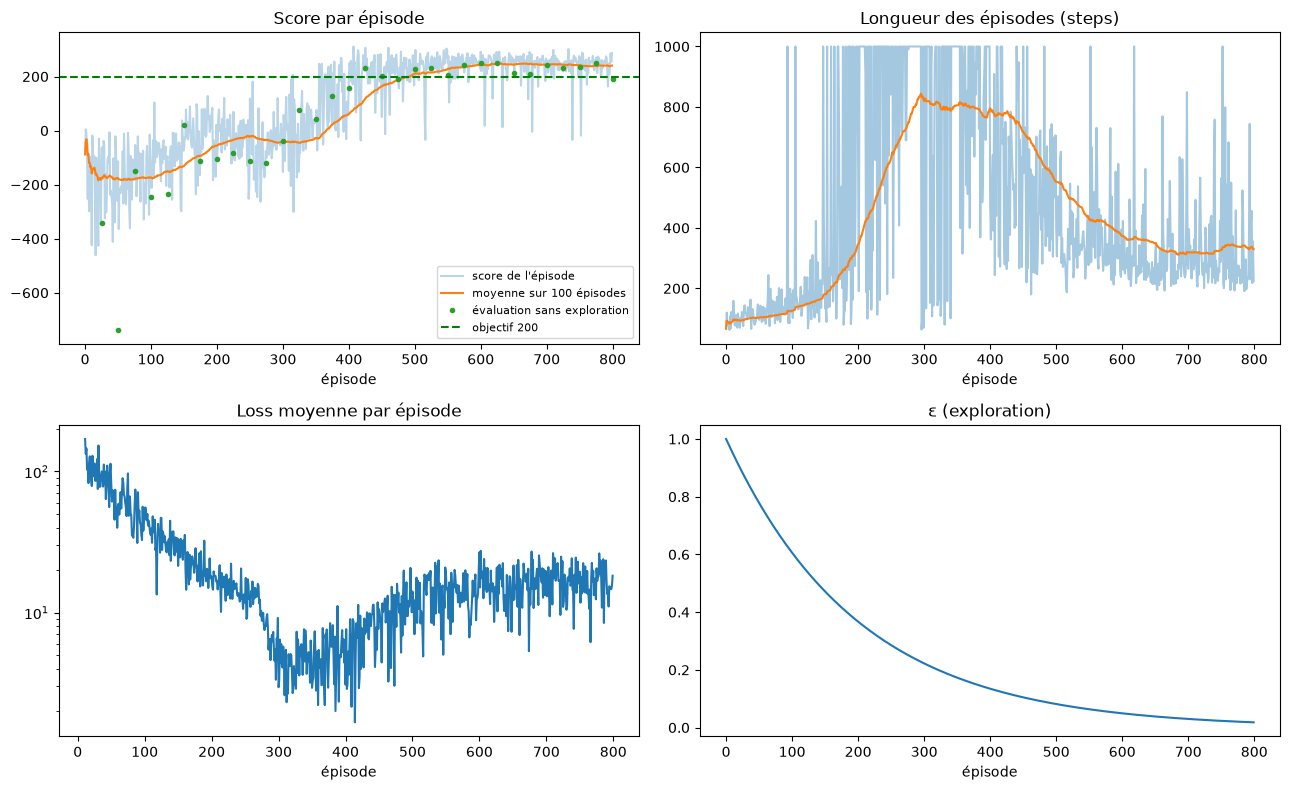

In [15]:
def moving_average(x, window=100):
    # Moyenne des `window` derniers épisodes, pour chaque épisode
    result = []
    for i in range(len(x)):
        start = max(0, i - window + 1)
        result.append(np.mean(x[start:i + 1]))
    return result


fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(history["reward"], alpha=0.3, label="score de l'épisode")
axes[0, 0].plot(moving_average(history["reward"]), label="moyenne sur 100 épisodes")
axes[0, 0].plot(history["eval_episode"], history["eval_score"], "o", markersize=3, label="évaluation sans exploration")
axes[0, 0].axhline(200, color="green", linestyle="--", label="objectif 200")
axes[0, 0].set_title("Score par épisode"); axes[0, 0].set_xlabel("épisode"); axes[0, 0].legend(fontsize=8)

axes[0, 1].plot(history["length"], alpha=0.4)
axes[0, 1].plot(moving_average(history["length"]))
axes[0, 1].set_title("Longueur des épisodes (steps)"); axes[0, 1].set_xlabel("épisode")

axes[1, 0].plot(history["loss"])
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Loss moyenne par épisode"); axes[1, 0].set_xlabel("épisode")

axes[1, 1].plot(history["epsilon"])
axes[1, 1].set_title("ε (exploration)"); axes[1, 1].set_xlabel("épisode")

plt.tight_layout(); plt.show()

**Lecture des courbes :**
- **Score** : la moyenne part d'environ -180 (comme l'agent aléatoire) et dépasse **200 vers l'épisode 500**.
  À la fin, elle est autour de 240. Les points verts (évaluations sur 10 épisodes) restent assez dispersés :
  il faudra une évaluation plus longue (100 épisodes) pour mesurer le vrai niveau de l'agent.
- **Longueur** : d'abord courte (l'agent s'écrase vite), puis proche de 1000 vers l'épisode 300 (l'agent plane sans se poser),
  puis elle redescend quand il apprend à atterrir.
- **Loss** : elle baisse, puis remonte à partir de l'épisode ~400. Ce n'est pas un problème : quand l'agent commence
  à atterrir, il gagne plus de points, ses Q-values deviennent plus grandes, donc les écarts aussi.
  Pour un DQN, c'est le **score** qui montre si l'agent progresse, pas la loss.
- **ε** : il baisse comme prévu, de 1 à environ 0.02.

### Causes de fin d'épisode pendant l'entraînement

crash : [95, 82, 21, 8, 2, 2, 3, 1]
out : [4, 2, 11, 7, 0, 0, 0, 0]
rest : [0, 0, 2, 27, 90, 97, 96, 98]
truncated : [1, 16, 66, 58, 8, 1, 1, 1]


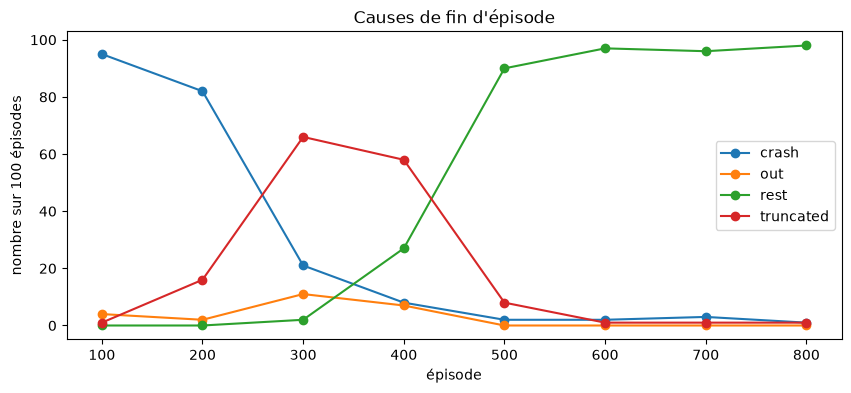

In [16]:
# On compte chaque cause de fin par tranche de 100 épisodes
blocks = range(0, len(history["reason"]), 100)

plt.figure(figsize=(10, 4))
for reason in END_REASONS:
    counts = [history["reason"][i:i + 100].count(reason) for i in blocks]
    plt.plot([i + 100 for i in blocks], counts, marker="o", label=reason)
    print(reason, ":", counts)
plt.xlabel("épisode"); plt.ylabel("nombre sur 100 épisodes"); plt.title("Causes de fin d'épisode")
plt.legend(); plt.show()

**Lecture :** on voit **trois phases** :
1. **Épisodes 1 à 200 : l'agent s'écrase** presque à chaque fois.
2. **Épisodes 200 à 400 : il plane.** Il a compris que s'écraser coûte cher, mais ne sait pas encore se poser :
   beaucoup d'épisodes sont coupés à 1000 steps (`truncated`).
3. **À partir de l'épisode 400 : il se pose** (`rest`) dans plus de 90 % des épisodes.

La phase 2 montre pourquoi il faut stocker `done = terminated` : à ce moment-là, beaucoup d'épisodes sont seulement coupés,
pas vraiment finis.

## 9. Évaluation sur 100 épisodes

Pendant l'entraînement, on a sauvegardé la meilleure version du réseau dans `models/dqn.pt`.
On la **recharge depuis le fichier** (ça vérifie aussi que la sauvegarde marche), puis on la fait jouer
**100 épisodes de suite, sans exploration** (ε = 0).

On utilise les graines 2000 à 2099 : elles n'ont servi ni à l'entraînement, ni aux évaluations régulières
(graines 1000+). L'agent est donc testé sur des parties qu'il n'a jamais vues.

Moyenne sur 100 épisodes : 244.4
Écart-type : 50.7
Minimum : -10.2 | Maximum : 295.0
Épisodes au-dessus de 200 : 90 sur 100
Causes de fin : Counter({'rest': 96, 'truncated': 3, 'crash': 1})


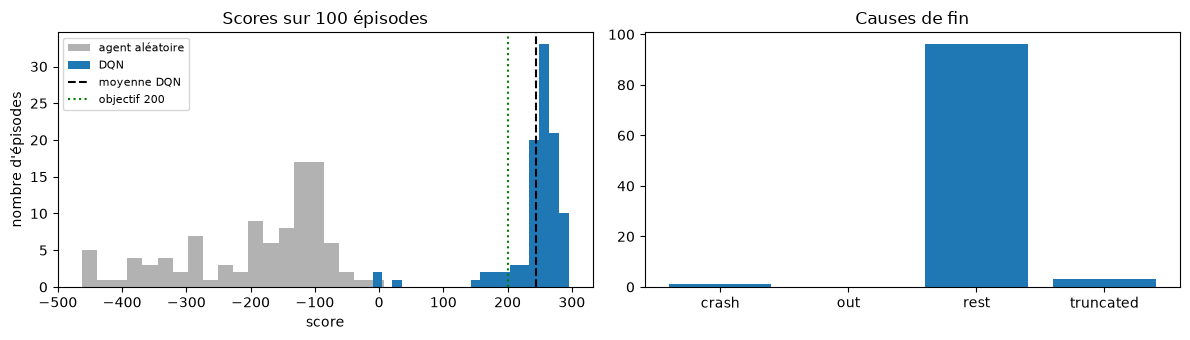

In [17]:
def test_agent(model_path, n_episodes=100):
    # Recharge un modèle sauvegardé et le fait jouer n_episodes sans exploration (graines 2000+)
    agent = DQNAgent(STATE_DIM, N_ACTIONS)
    agent.q_net.load_state_dict(torch.load(model_path))
    env = make_env()
    scores, reasons = [], []
    for i in range(n_episodes):
        score, steps, reason = run_episode(env, lambda s: agent.act(s, epsilon=0.0), seed=2000 + i)
        scores.append(score)
        reasons.append(reason)
    env.close()
    return scores, reasons


test_scores, test_reasons = test_agent(MODEL_PATH)

print("Moyenne sur 100 épisodes :", round(np.mean(test_scores), 1))
print("Écart-type :", round(np.std(test_scores), 1))
print("Minimum :", round(np.min(test_scores), 1), "| Maximum :", round(np.max(test_scores), 1))
print("Épisodes au-dessus de 200 :", sum(s >= 200 for s in test_scores), "sur 100")
print("Causes de fin :", Counter(test_reasons))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(scores, bins=20, color="gray", alpha=0.6, label="agent aléatoire")
axes[0].hist(test_scores, bins=20, label="DQN")
axes[0].axvline(np.mean(test_scores), color="k", linestyle="--", label="moyenne DQN")
axes[0].axvline(200, color="green", linestyle=":", label="objectif 200")
axes[0].set_xlabel("score"); axes[0].set_ylabel("nombre d'épisodes"); axes[0].legend(fontsize=8)
axes[0].set_title("Scores sur 100 épisodes")
axes[1].bar(END_REASONS, [test_reasons.count(r) for r in END_REASONS])
axes[1].set_title("Causes de fin")
plt.tight_layout(); plt.show()

**Résultat : l'environnement est résolu.** Sur 100 épisodes jamais vus, l'agent fait **244.4 en moyenne**
(écart-type 50.7), contre environ -190 pour l'agent aléatoire. 90 épisodes sur 100 dépassent 200,
et l'agent se pose dans 96 épisodes sur 100.

**Ce qui reste imparfait :** 1 crash et 3 épisodes où l'agent plane jusqu'à la limite de 1000 steps.
Ce sont ces quelques épisodes ratés qui font baisser la moyenne et augmentent l'écart-type.

## 10. Résultats sur plusieurs seeds

Un seul entraînement peut avoir eu de la chance. On refait **exactement le même entraînement** avec les seeds 1 et 2,
puis on teste chaque agent sur les **mêmes 100 épisodes** (graines 2000+).

Pour chaque seed, on regarde :
- le **score de test** sur 100 épisodes ;
- à partir de **quel épisode** la moyenne des 100 derniers épisodes dépasse 200, et après **combien de steps** ;
- le **temps d'entraînement**.

Les modèles des seeds 1 et 2 sont rangés dans `checkpoints/` (pas rendus) : le modèle livré reste `models/dqn.pt` (seed 0).

In [18]:
os.makedirs("checkpoints", exist_ok=True)


def first_episode_above_200(rewards):
    # Premier épisode où la moyenne des 100 derniers épisodes atteint 200
    averages = moving_average(rewards)
    for i in range(99, len(averages)):
        if averages[i] >= 200:
            return i + 1
    return None


def summary(history, test_scores):
    solved = first_episode_above_200(history["reward"])
    return {
        "test_mean": float(np.mean(test_scores)),
        "test_std": float(np.std(test_scores)),
        "above_200": int(sum(s >= 200 for s in test_scores)),
        "solved_episode": solved,
        "solved_steps": history["total_steps"][solved - 1] if solved else None,
        "train_time": history["train_time"],
    }


def print_table(results):
    print("seed | test (100 ép.) | ≥ 200 | moyenne ≥ 200 à l'épisode | steps   | temps")
    for seed, r in results.items():
        print(seed, "   |", round(r["test_mean"], 1), "±", round(r["test_std"], 1), " |", r["above_200"],
              "  |", r["solved_episode"], "                      |", r["solved_steps"], "|",
              round(r["train_time"] / 60, 1), "min")
    means = [r["test_mean"] for r in results.values()]
    print("Moyenne des seeds :", round(np.mean(means), 1), "±", round(np.std(means), 1))


seed_histories = {0: history}
seed_results = {0: summary(history, test_scores)}
for seed in [1, 2]:
    path = f"checkpoints/dqn_seed{seed}.pt"
    _, seed_histories[seed] = train(CONFIG, seed=seed, save_path=path, verbose=False)
    scores_seed, _ = test_agent(path)
    seed_results[seed] = summary(seed_histories[seed], scores_seed)

print_table(seed_results)

seed | test (100 ép.) | ≥ 200 | moyenne ≥ 200 à l'épisode | steps   | temps
0    | 244.4 ± 50.7  | 90   | 493                       | 259764 | 1.1 min
1    | 246.3 ± 26.1  | 98   | 585                       | 332210 | 1.2 min
2    | 250.5 ± 49.8  | 95   | 707                       | 360958 | 1.1 min
Moyenne des seeds : 247.1 ± 2.5


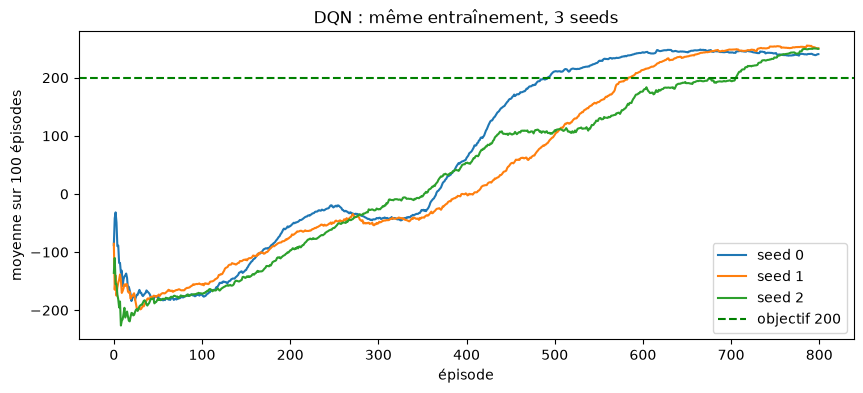

In [19]:
plt.figure(figsize=(10, 4))
for seed, h in seed_histories.items():
    plt.plot(moving_average(h["reward"]), label=f"seed {seed}")
plt.axhline(200, color="green", linestyle="--", label="objectif 200")
plt.xlabel("épisode"); plt.ylabel("moyenne sur 100 épisodes"); plt.title("DQN : même entraînement, 3 seeds")
plt.legend(); plt.show()

# On garde un résumé pour la comparaison avec le PPO (notebook ppo.ipynb)
os.makedirs("results", exist_ok=True)
with open("results/dqn_summary.json", "w") as f:
    json.dump(seed_results, f, indent=2)

**Lecture :**
- **Les 3 seeds résolvent l'environnement** : 244.4, 246.3 et 250.5 sur 100 épisodes de test, soit **247.1 ± 2.5** en moyenne.
  Le résultat ne dépend pas d'une seed chanceuse.
- La vitesse d'apprentissage varie plus : la moyenne dépasse 200 entre l'épisode **493** et l'épisode **707**
  (entre 260 000 et 361 000 steps). Les trois courbes ont la même forme, mais décalée dans le temps.
- Chaque entraînement prend environ **1 minute** sur CPU.

## 11. Expérience : fréquence de mise à jour du target network

**Question :** à quelle fréquence faut-il recopier le réseau dans le target network ?

On ne change **qu'un seul paramètre**, `target_update`, et on garde tout le reste identique :
- **100** : la cible est recopiée très souvent, elle bouge presque autant que le réseau principal ;
- **1 000** : notre valeur de départ ;
- **5 000** : la cible est recopiée rarement, elle reste fixe longtemps.

Chaque variante est entraînée sur les **3 mêmes seeds** et testée sur les **mêmes 100 épisodes**.

In [20]:
experiment = {1000: seed_results}
experiment_histories = {1000: seed_histories}
for target_update in [100, 5000]:
    config = {**CONFIG, "target_update": target_update}
    experiment[target_update], experiment_histories[target_update] = {}, {}
    for seed in [0, 1, 2]:
        path = f"checkpoints/dqn_target{target_update}_seed{seed}.pt"
        _, h = train(config, seed=seed, save_path=path, verbose=False)
        scores_exp, _ = test_agent(path)
        experiment[target_update][seed] = summary(h, scores_exp)
        experiment_histories[target_update][seed] = h

for target_update in [100, 1000, 5000]:
    print("\n=== target_update =", target_update, "===")
    print_table(experiment[target_update])


=== target_update = 100 ===
seed | test (100 ép.) | ≥ 200 | moyenne ≥ 200 à l'épisode | steps   | temps
0    | 256.3 ± 40.0  | 95   | 439                       | 225097 | 1.0 min
1    | 250.3 ± 39.3  | 93   | 444                       | 232072 | 1.1 min
2    | 238.8 ± 67.6  | 91   | 504                       | 276344 | 1.1 min
Moyenne des seeds : 248.5 ± 7.3

=== target_update = 1000 ===
seed | test (100 ép.) | ≥ 200 | moyenne ≥ 200 à l'épisode | steps   | temps
0    | 244.4 ± 50.7  | 90   | 493                       | 259764 | 1.1 min
1    | 246.3 ± 26.1  | 98   | 585                       | 332210 | 1.2 min
2    | 250.5 ± 49.8  | 95   | 707                       | 360958 | 1.1 min
Moyenne des seeds : 247.1 ± 2.5

=== target_update = 5000 ===
seed | test (100 ép.) | ≥ 200 | moyenne ≥ 200 à l'épisode | steps   | temps
0    | 6.4 ± 86.1  | 0   | None                       | None | 1.3 min
1    | 62.6 ± 156.8  | 30   | None                       | None | 1.2 min
2    | 17.4 ± 91.5  | 2 

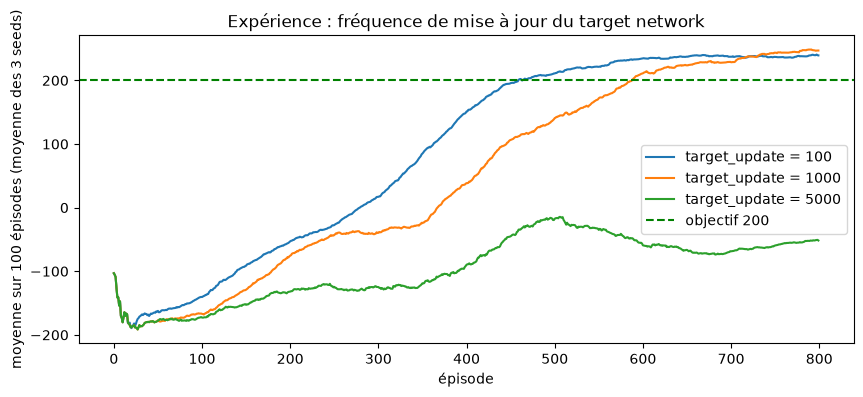

In [21]:
plt.figure(figsize=(10, 4))
for target_update in [100, 1000, 5000]:
    curves = [moving_average(h["reward"]) for h in experiment_histories[target_update].values()]
    plt.plot(np.mean(curves, axis=0), label=f"target_update = {target_update}")
plt.axhline(200, color="green", linestyle="--", label="objectif 200")
plt.xlabel("épisode"); plt.ylabel("moyenne sur 100 épisodes (moyenne des 3 seeds)")
plt.title("Expérience : fréquence de mise à jour du target network")
plt.legend(); plt.show()

**Résultats de l'expérience :**

| `target_update` | Score de test (3 seeds) | Moyenne ≥ 200 atteinte à l'épisode | Steps |
|---|---|---|---|
| 100 | **248.5** ± 7.3 | 439 à 504 | 225 000 à 276 000 |
| 1 000 (notre choix) | 247.1 ± 2.5 | 493 à 707 | 260 000 à 361 000 |
| 5 000 | **28.8** ± 24.3 | jamais en 800 épisodes | — |

- **5 000 est un échec** : la cible n'est recopiée que tous les 5 000 updates (20 000 steps). Elle reste bloquée sur
  de vieilles valeurs trop longtemps, et l'agent apprend beaucoup trop lentement : il n'atteint jamais 200.
- **100 apprend plus vite** que 1 000 (environ 100 épisodes plus tôt), pour un score final presque identique.
  L'écart de score final (248.5 contre 247.1) est plus petit que la variation entre seeds : on ne peut pas dire que l'un est meilleur à la fin.
- **Conclusion :** la cible doit être recopiée **assez souvent**. Notre valeur de 1 000 marche, mais 100 aurait été un meilleur choix
  pour la vitesse. On garde quand même le modèle à 1 000 comme modèle livré, car il a été choisi avant l'expérience :
  le remplacer après avoir vu les scores de test reviendrait à choisir le modèle sur les épisodes de test.

## 12. Conclusion

**Résultat.** L'agent DQN **résout LunarLander-v3** : **244.4** sur 100 épisodes jamais vus pour le modèle livré,
et **247.1 ± 2.5** sur 3 seeds, contre environ **-190** pour l'agent aléatoire. Il se pose dans 96 épisodes sur 100.
Il apprend en environ 500 à 700 épisodes (260 000 à 360 000 steps), soit un peu plus d'une minute d'entraînement.

**Ce qu'on a appris :**
- L'apprentissage se fait en **trois phases** : l'agent s'écrase, puis il plane pour éviter le crash, puis il se pose.
  Pendant la phase où il plane, beaucoup d'épisodes sont **tronqués** : c'est là qu'il est important de stocker
  `done = terminated` et pas `truncated`.
- La **loss ne mesure pas la performance** d'un DQN : elle remonte quand l'agent commence à réussir, car ses Q-values grandissent.
  C'est le score qui montre la progression.
- La **fréquence de mise à jour du target network** compte beaucoup : trop rare (5 000), l'agent n'apprend presque pas ;
  plus fréquente (100), il apprend plus vite.

**Limites :**
- L'agent n'est pas parfait : quelques épisodes où il plane jusqu'à la limite de temps ou s'écrase, d'où un écart-type d'environ 50.
- Les évaluations pendant l'entraînement (10 épisodes) sont bruitées : le « meilleur modèle » est choisi avec de l'incertitude.
- L'expérience ne porte que sur 3 seeds par variante.

**Pistes d'amélioration :** mettre à jour le target network plus souvent, évaluer sur plus d'épisodes pendant l'entraînement,
ou essayer des variantes connues comme le Double DQN. La comparaison avec le PPO sera faite dans `ppo.ipynb`.